# EnergyMind - Phase 1 exploration

What the street dataset looks like before any model is built: how the homes were cleaned and chosen,
their daily and seasonal patterns, the effect of temperature, the simulated network, and what every
injected problem does to the readings.

Every number below is read from `data/`. Rebuild everything with `python src/run_all.py`;
the methods and limits are in `data/DATA_CARD.md`, the checks in `data/checks_report.txt`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA, FIG = ROOT / "data", ROOT / "figures"
FIG.mkdir(exist_ok=True)

# Colours: validated categorical slots 1-3 for the three phases; grey = normal reference.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, INK, MUTED, SURFACE = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb"
PHASE_COLOURS = {"A": BLUE, "B": ORANGE, "C": AQUA}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 1.8, "legend.frameon": False, "font.size": 9.5,
})


def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor=SURFACE)


r18 = pd.read_parquet(DATA / "readings_2018.parquet")
r19 = pd.read_parquet(DATA / "readings_2019.parquet")
readings = pd.concat([r18, r19], ignore_index=True)
normal = pd.read_parquet(DATA / "normal" / "readings_normal.parquet")
tx = pd.read_parquet(DATA / "transformer.parquet")
tx_n = pd.read_parquet(DATA / "normal" / "transformer_normal.parquet")
wiring = pd.read_csv(DATA / "wiring.csv", dtype={"zip_code": str})
homes = pd.read_csv(DATA / "homes.csv", dtype={"zip_code": str})
ctx = pd.read_csv(DATA / "context.csv", parse_dates=["timestamp"])
answers = pd.read_csv(DATA / "answers.csv", parse_dates=["start", "end"])
log = pd.read_csv(DATA / "selection_log.csv")
print(f"{readings.home_id.nunique()} homes | {readings.timestamp.nunique():,} hours | "
      f"{len(readings):,} meter readings | {len(answers)} injected problems")

75 homes | 17,520 hours | 1,314,000 meter readings | 125 injected problems


## 1. Cleaning: how the homes were chosen

`src/step1_clean_select.py` starts from every GoiEner series and keeps only homes whose normal days look
normal: households without solar panels, complete hourly data for 2018-2019, few estimated hours, plausible
yearly use, no sharp change between the two years, and no unexplained zeros. The 75 homes are then drawn
at random (fixed seed) from the province with the most candidates.

,stage,rule,homes_left
0,metadata,all series in metadata.csv,25559
1,metadata,household (CNAE 98xx),20794
2,metadata,no self-consumption (no solar panels),20655
3,metadata,"household tariff (2.x, up to 15 kW)",20477
4,metadata,series dates cover 2018-2019,6950
5,readings,series found in imp-pre.tzst,6923
6,readings,complete hourly 2018-2019 (gaps up to 48 h fil...,6899
7,readings,estimated hours at most 5%,6858
8,readings,yearly use 600-12000 kWh in 2018 and in 2019,6193
9,readings,2019 vs 2018 change at most 35%,5840


Hours estimated by GoiEner: 0.02% of all home-hours (worst home 0.02%). No problem is ever injected on these hours.


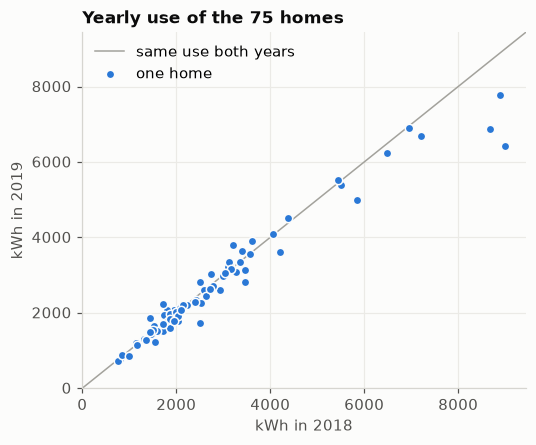

In [2]:
display(log)
est = r18.groupby("home_id")["estimated"].mean()
print(f"Hours estimated by GoiEner: {readings['estimated'].mean():.2%} of all home-hours "
      f"(worst home {readings.groupby('home_id')['estimated'].mean().max():.2%}). "
      "No problem is ever injected on these hours.")

fig, ax = plt.subplots(figsize=(5.2, 4.2))
lim = [0, max(homes.kwh_2018.max(), homes.kwh_2019.max()) * 1.05]
ax.plot(lim, lim, color=GREY, lw=1, label="same use both years")
ax.scatter(homes.kwh_2018, homes.kwh_2019, s=30, color=BLUE, edgecolors=SURFACE, linewidths=1, label="one home", zorder=3)
ax.set(xlim=lim, ylim=lim, xlabel="kWh in 2018", ylabel="kWh in 2019", title="Yearly use of the 75 homes")
ax.legend(loc="upper left")
save(fig, "01_yearly_use.png")
plt.show()

## 2. Daily, weekly and seasonal patterns

Patterns are read from the normal simulation, so injected problems do not distort them.

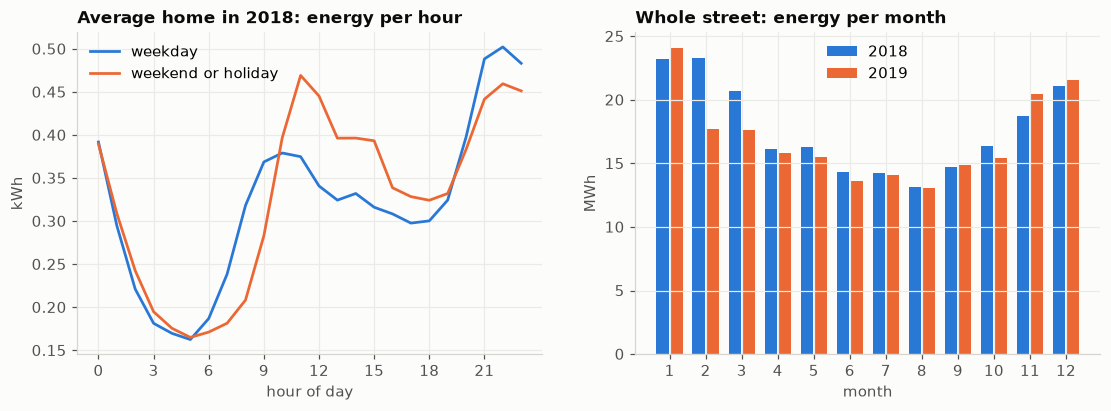

Weekday peak at 22:00 (0.50 kWh); night minimum 0.16 kWh. Highest month: 1, lowest: 8.


In [3]:
n = normal.merge(ctx[["timestamp", "is_weekend", "is_holiday", "temperature_c"]], on="timestamp")
n["hour"] = n.timestamp.dt.hour
n["day_type"] = np.where((n.is_weekend == 1) | (n.is_holiday == 1), "weekend or holiday", "weekday")
prof = n[n.timestamp.dt.year == 2018].groupby(["day_type", "hour"])["kwh"].mean().unstack(0)
monthly = n.groupby([n.timestamp.dt.month.rename("month"), n.timestamp.dt.year.rename("year")])["kwh"].sum().unstack() / 1000

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(prof.index, prof["weekday"], color=BLUE, label="weekday")
ax[0].plot(prof.index, prof["weekend or holiday"], color=ORANGE, label="weekend or holiday")
ax[0].set(title="Average home in 2018: energy per hour", xlabel="hour of day", ylabel="kWh", xticks=range(0, 24, 3))
ax[0].legend()
w = 0.38
ax[1].bar(monthly.index - w / 2, monthly[2018], w * 0.92, color=BLUE, label="2018")
ax[1].bar(monthly.index + w / 2, monthly[2019], w * 0.92, color=ORANGE, label="2019")
ax[1].set(title="Whole street: energy per month", xlabel="month", ylabel="MWh", xticks=range(1, 13))
ax[1].legend()
save(fig, "02_patterns.png")
plt.show()

peak_h = prof["weekday"].idxmax()
print(f"Weekday peak at {peak_h}:00 ({prof['weekday'].max():.2f} kWh); night minimum "
      f"{prof['weekday'].min():.2f} kWh. Highest month: {monthly.mean(axis=1).idxmax()}, lowest: {monthly.mean(axis=1).idxmin()}.")

## 3. Effect of temperature

Daily street energy against the daily mean outdoor temperature (Open-Meteo, capital of the province).

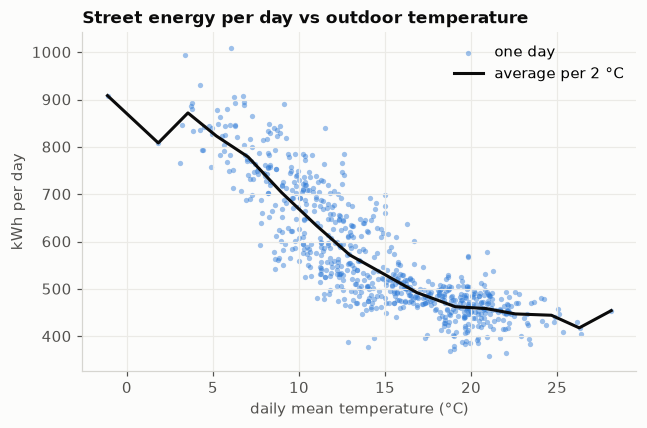

Days below 8 °C use +63% energy compared with days between 14 and 20 °C.


In [4]:
daily = n.groupby(n.timestamp.dt.normalize()).agg(kwh=("kwh", "sum"), temp=("temperature_c", "mean"))
if daily["temp"].notna().any():
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.scatter(daily.temp, daily.kwh, s=12, color=BLUE, alpha=0.45, linewidths=0, label="one day")
    edges = np.arange(np.floor(daily.temp.min()), np.ceil(daily.temp.max()) + 2, 2)
    trend = daily.groupby(pd.cut(daily.temp, edges), observed=True).agg(t=("temp", "mean"), k=("kwh", "mean"))
    ax.plot(trend.t, trend.k, color=INK, lw=2, label="average per 2 °C")
    ax.set(title="Street energy per day vs outdoor temperature", xlabel="daily mean temperature (°C)", ylabel="kWh per day")
    ax.legend()
    save(fig, "03_temperature.png")
    plt.show()
    cold, mild = daily[daily.temp < 8].kwh.mean(), daily[(daily.temp >= 14) & (daily.temp <= 20)].kwh.mean()
    print(f"Days below 8 °C use {100 * (cold / mild - 1):+.0f}% energy compared with days between 14 and 20 °C.")
else:
    print("temperature_c is empty in this build (the download failed). Rerun `python src/run_all.py` with internet.")

## 4. The simulated street (normal values)

Energy is real; voltage, current and the transformer are simulated with the formulas in `data/DATA_CARD.md`.
Two sanity checks: voltage falls along each cable, and the transformer always measures a little more than the sum of the meters
(cable losses + meter noise). That gap on clean data is the noise floor any theft detection has to beat.

phase,A,B,C
cable,,,
1,9,8,8
2,8,9,8
3,8,8,9


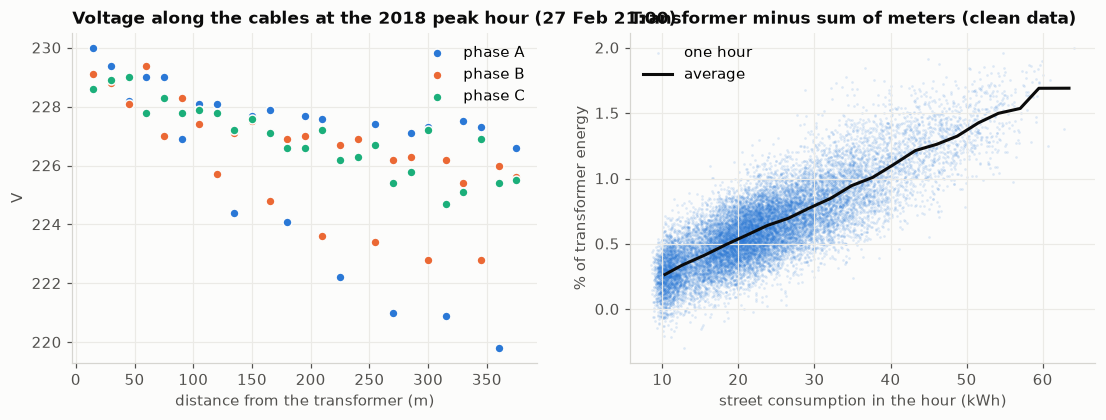

Gap on clean data: mean 0.64%, 95% of hours below 1.26%. It grows with load because cable losses grow with the square of the current.


In [5]:
display(wiring.groupby(["cable", "phase"]).size().unstack().rename_axis(index="cable", columns="phase"))

tot_n = tx_n.set_index("timestamp")["energy_kwh_total"]
peak_time = tot_n[tot_n.index.year == 2018].idxmax()
at_peak = normal[normal.timestamp == peak_time].merge(wiring[["home_id", "phase", "distance_m"]], on="home_id")
meters = normal.groupby("timestamp")["kwh"].sum()
gap_pct = 100 * (tot_n - meters) / tot_n

fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for p, g in at_peak.groupby("phase"):
    ax[0].scatter(g.distance_m, g.voltage_v, s=34, color=PHASE_COLOURS[p], edgecolors=SURFACE, linewidths=1, label=f"phase {p}", zorder=3)
ax[0].set(title=f"Voltage along the cables at the 2018 peak hour ({peak_time:%d %b %H:00})",
          xlabel="distance from the transformer (m)", ylabel="V")
ax[0].legend()
ax[1].scatter(meters, gap_pct, s=3, color=BLUE, alpha=0.15, linewidths=0, label="one hour")
trend = pd.DataFrame({"x": meters, "y": gap_pct}).groupby(pd.cut(meters, 20), observed=True).mean()
ax[1].plot(trend.x, trend.y, color=INK, lw=2, label="average")
ax[1].set(title="Transformer minus sum of meters (clean data)", xlabel="street consumption in the hour (kWh)",
          ylabel="% of transformer energy")
ax[1].legend()
save(fig, "04_street.png")
plt.show()
print(f"Gap on clean data: mean {gap_pct.mean():.2f}%, 95% of hours below {gap_pct.quantile(0.95):.2f}%. "
      "It grows with load because cable losses grow with the square of the current.")

## 5. What each injected problem looks like

One example of every type from `data/answers.csv` (the most obvious size when there is one). Grey: the normal
simulation. Blue: what the meter, or the transformer, reports. The shaded band is the problem window.

period,practice,final_test
type,,
holiday_absence,6,6
impossible_value,6,6
missing_all,3,3
missing_one,6,6
new_ac,2,4
outage_phase,4,4
outage_street,3,3
over_reporting,0,9
stuck_meter,6,6


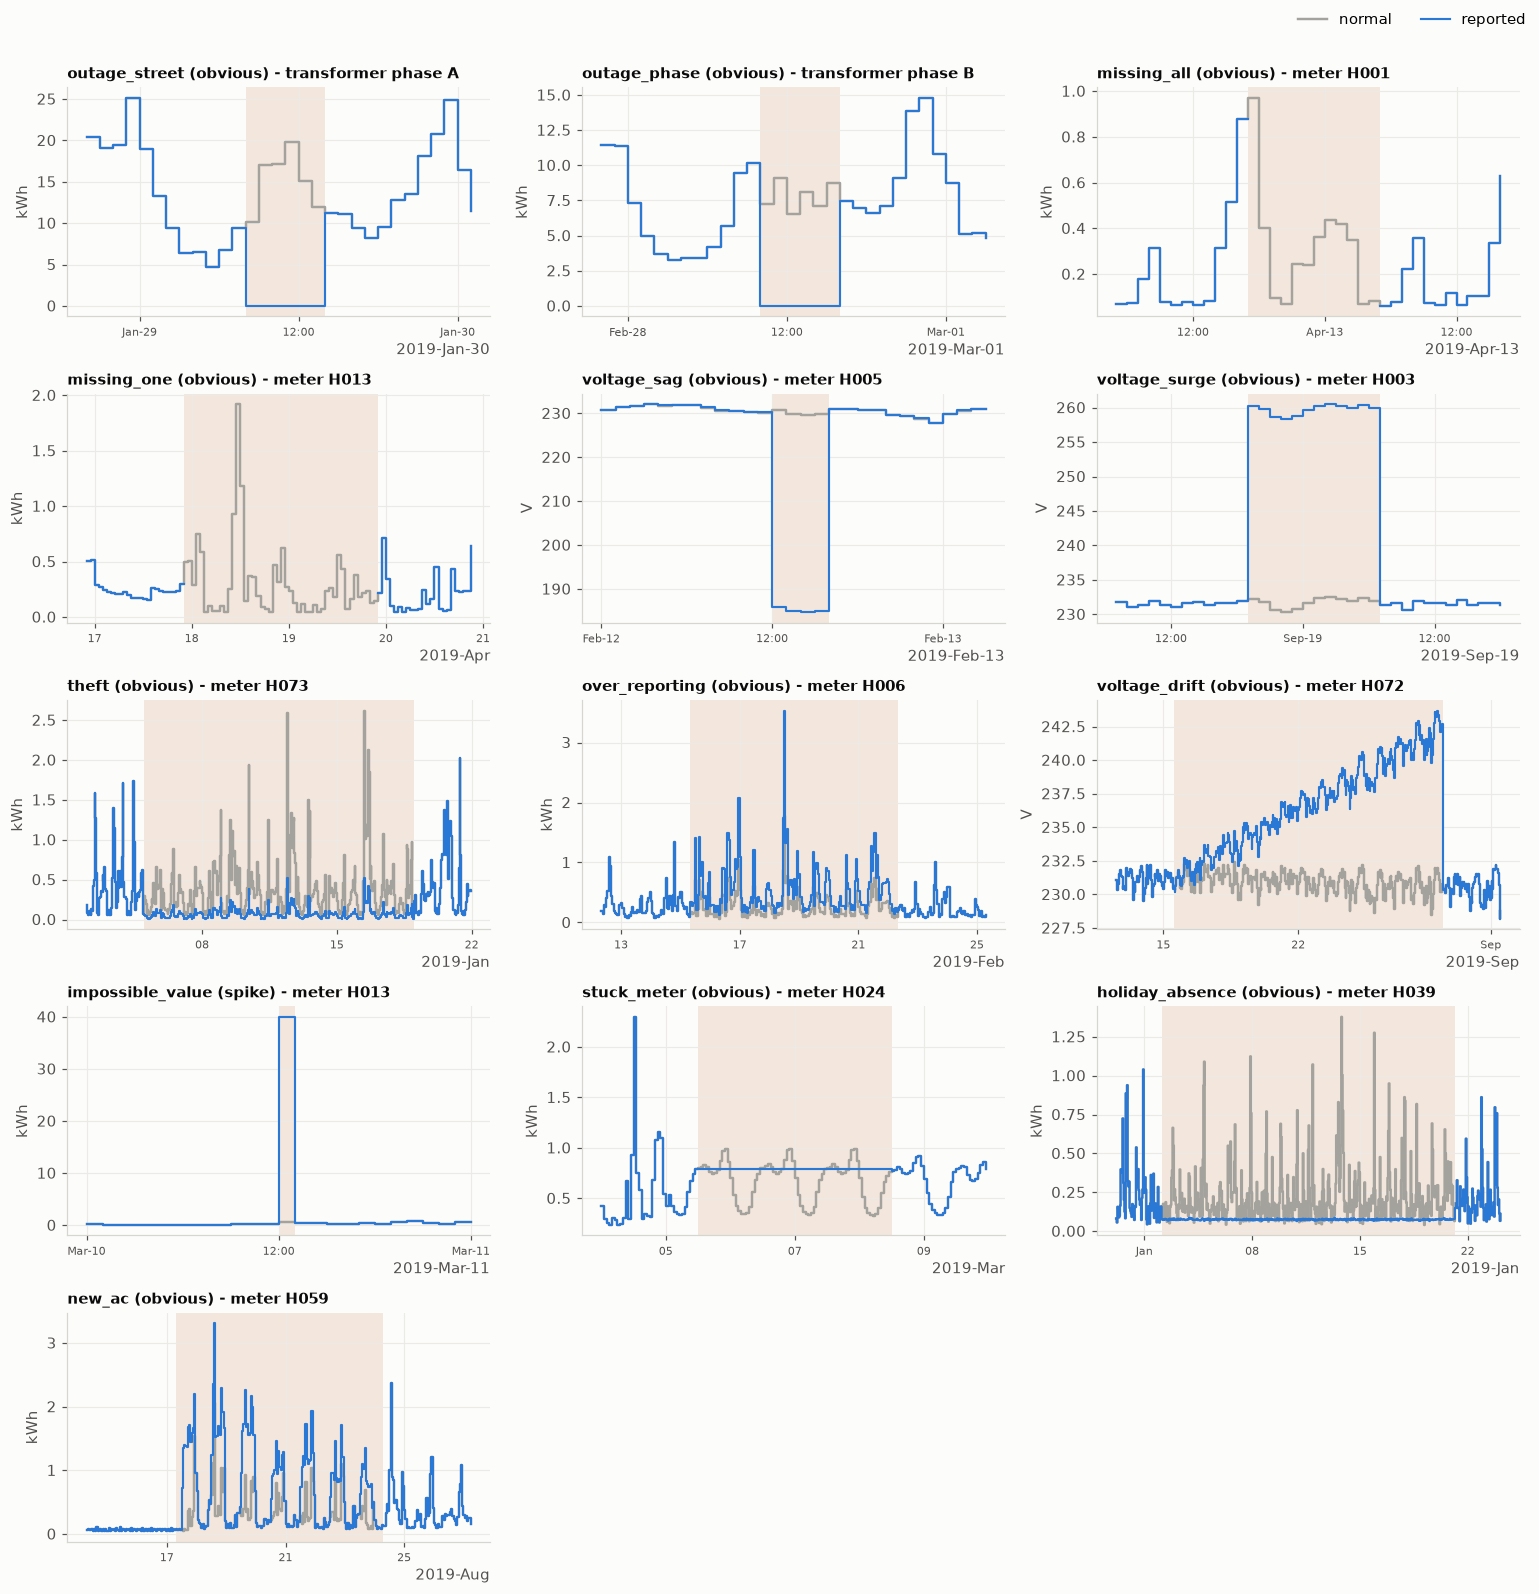

In [6]:
display(pd.crosstab(answers.type, answers.period).reindex(columns=["practice", "final_test"]))

nr = normal.set_index(["home_id", "timestamp"]).sort_index()
fr = readings.set_index(["home_id", "timestamp"]).sort_index()
txn, txf = tx_n.set_index("timestamp"), tx.set_index("timestamp")
SHOW = {"outage_street": "tx", "outage_phase": "tx", "missing_all": "kwh", "missing_one": "kwh",
        "voltage_sag": "voltage_v", "voltage_surge": "voltage_v", "theft": "kwh", "over_reporting": "kwh",
        "voltage_drift": "voltage_v", "impossible_value": "kwh", "stuck_meter": "kwh",
        "holiday_absence": "kwh", "new_ac": "kwh"}
types = [t for t in SHOW if (answers.type == t).any()]
cols = 3
rows = int(np.ceil(len(types) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 2.9 * rows))
for ax, t in zip(axes.flat, types):
    ex = answers[answers.type == t]
    pick = ex[ex.level.isin(["obvious", "spike"])]
    row = (pick if len(pick) else ex).iloc[0]
    pad = pd.Timedelta(hours=int(min(max(12, row.hours * 0.5), 72)))
    t0, t1 = row.start - pad, row.end + pad
    home = row.affected_homes.split(";")[0]
    var = SHOW[t]
    if t == "impossible_value" and row.level == "voltage_zero_with_load":
        var = "voltage_v"
    if var == "tx":
        col = f"energy_kwh_{row.phase[0]}"
        a, b = txn.loc[t0:t1, col], txf.loc[t0:t1, col]
        what, unit = f"transformer phase {row.phase[0]}", "kWh"
    else:
        a = nr.loc[(home, slice(t0, t1)), var].droplevel(0)
        b = fr.loc[(home, slice(t0, t1)), var].droplevel(0)
        what, unit = f"meter {home}", "kWh" if var == "kwh" else "V"
    ax.axvspan(row.start, row.end + pd.Timedelta(hours=1), color="#f3e6dc", lw=0)
    ax.plot(a.index, a.values, color=GREY, lw=1.6, label="normal", drawstyle="steps-post")
    ax.plot(b.index, b.values, color=BLUE, lw=1.4, label="reported", drawstyle="steps-post")
    ax.set_title(f"{t} ({row.level}) - {what}", fontsize=9.5)
    ax.set_ylabel(unit)
    ax.tick_params(axis="x", labelsize=7.5, rotation=0)
    loc = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
for ax in list(axes.flat)[len(types):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "05_problems.png")
plt.show()

## 6. Honest meters that repeat a value (threshold of the stuck-meter rule)

A stuck meter keeps repeating its whole last reading: energy, voltage and current. To flag it without false alarms,
the rule must only fire on repeats that honest meters never produce. 2018 shows how often honest meters repeat their
energy reading by chance, and whether they ever repeat their whole reading.

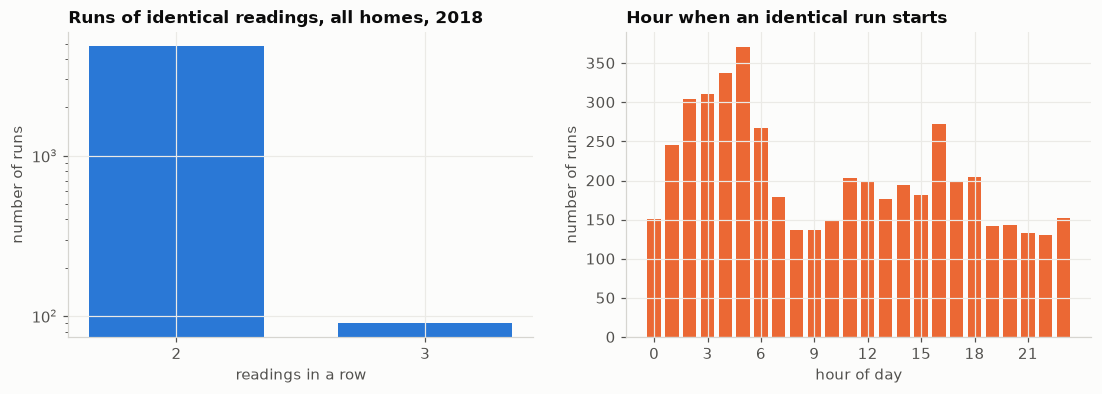

Energy alone: 4919 runs of 2+ identical readings (66 per home per year); longest 3 hours; 35% start between 00:00 and 05:59.
Whole reading (energy, voltage and current all identical to the previous hour): 271 times in 2018; longest run 3 readings.


In [7]:
def equal_runs(x, ok):
    same = np.r_[False, (x[1:] == x[:-1]) & ok[1:] & ok[:-1]]
    edges = np.diff(np.r_[0, same.astype(int), 0])
    s, e = np.where(edges == 1)[0], np.where(edges == -1)[0]
    return e - s + 1, s - 1

lengths, start_hours = [], []
for _, g in r18.sort_values(["home_id", "timestamp"]).groupby("home_id"):
    L, s = equal_runs(g["kwh"].to_numpy(), g["estimated"].to_numpy() == 0)
    lengths.append(L)
    start_hours.append(g["timestamp"].dt.hour.to_numpy()[s])
L, Hs = np.concatenate(lengths), np.concatenate(start_hours)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
cap = np.minimum(L, 8)
vals, counts = np.unique(cap, return_counts=True)
ax[0].bar(vals, counts, color=BLUE, width=0.7)
ax[0].set(title="Runs of identical readings, all homes, 2018", xlabel="readings in a row", ylabel="number of runs", yscale="log")
ax[0].set_xticks(vals, [str(v) if v < 8 else "8+" for v in vals])
ax[1].bar(range(24), np.bincount(Hs, minlength=24), color=ORANGE, width=0.75)
ax[1].set(title="Hour when an identical run starts", xlabel="hour of day", ylabel="number of runs", xticks=range(0, 24, 3))
save(fig, "06_repeats.png")
plt.show()
print(f"Energy alone: {len(L)} runs of 2+ identical readings ({len(L) / r18.home_id.nunique():.0f} per home per year); "
      f"longest {L.max() if len(L) else 0} hours; {np.mean(Hs < 6):.0%} start between 00:00 and 05:59.")

whole, longest_whole = 0, 1
for _, g in r18.sort_values(["home_id", "timestamp"]).groupby("home_id"):
    e, v, a = (g[c].to_numpy() for c in ("kwh", "voltage_v", "current_a"))
    m = g["estimated"].to_numpy() == 0
    same = (e[1:] == e[:-1]) & (v[1:] == v[:-1]) & (a[1:] == a[:-1]) & m[1:] & m[:-1]
    whole += int(same.sum())
    if same.any():
        edges = np.diff(np.r_[0, same.astype(int), 0])
        longest_whole = max(longest_whole, int((np.where(edges == -1)[0] - np.where(edges == 1)[0]).max()) + 1)
print(f"Whole reading (energy, voltage and current all identical to the previous hour): {whole} times in 2018; "
      f"longest run {longest_whole} readings.")

## 7. What we take into Phase 2

- **Noise floor.** The clean-data gap between the transformer and the meters (section 4) is what cable losses and meter noise
  look like. A theft smaller than this gap on one phase cannot be seen from the energy balance alone; per-home voltage and current
  are the second signal.
- **What "normal" depends on.** Hour of day, weekday vs weekend or holiday, season and temperature (sections 2-3) are the inputs of
  the normal-behaviour model.
- **Every problem leaves a different trace.** One home vs one phase vs the whole street, meter vs transformer, energy vs voltage
  (section 5): the verdict rules of the proposal are built on exactly these differences.
- **The stuck-meter rule checks the whole reading.** Energy alone can stay flat for hours in the source data (section 6),
  but a working meter's voltage always moves, so honest meters never repeat their whole reading.
- **Over-reporting is held out.** No rule is written for it. The final test checks whether the general signals above (the home's
  usual pattern, its neighbours, the street balance) still catch a meter that claims more energy than the transformer delivered.